# **Module 07: Hypothesis Testing**

---

## 📌 Overview

**Hypothesis Testing** provides the formal statistical framework used to make decisions based on sample evidence. Instead of relying solely on intuition or apparent differences in the data, this approach evaluates whether an observed effect — such as an increase in conversion rate for a new layout or a performance difference between two algorithms — is **statistically significant** or could have occurred purely by chance.

In this notebook, we will dive deeper into the logic of statistical decision-making, error control, and the practical application of the main parametric and non-parametric tests in Python.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Formulate statistical hypotheses accurately**, defining the null hypothesis ($H_0$) and alternative hypothesis ($H_1$) for one-tailed and two-tailed tests.
* **Interpret the significance level ($\alpha$), critical region, and p-value**, avoiding common misconceptions when communicating results.
* **Understand and balance decision errors** — Type I Error ($\alpha$) and Type II Error ($\beta$) — as well as evaluate **statistical power** ($1 - \beta$) and effect size.
* **Validate statistical assumptions** before choosing a test, checking for normality and homogeneity of variances.
* **Select and execute the appropriate test** for each scenario (one sample, two independent samples, paired samples, multiple groups, and categorical variables).
* **Implement end-to-end hypothesis testing workflows in Python** using `scipy.stats` and `statsmodels`.

---

## 🧭 Module Structure

1. **Logic of Hypothesis Testing** — Formulating $H_0$ and $H_1$, one-tailed vs. two-tailed tests, test statistics, and p-values.
2. **Decision Errors and Statistical Power** — Type I Error ($\alpha$), Type II Error ($\beta$), statistical power, and statistical vs. practical significance.
3. **Assumption Checking** — Normality tests (Shapiro-Wilk, Kolmogorov-Smirnov) and homogeneity of variances (Levene's test).
4. **Parametric Tests** — $Z$-test, Student's $t$-test (one-sample, independent, and paired), and ANOVA (Analysis of Variance).
5. **Non-Parametric and Association Tests** — Mann-Whitney U, Wilcoxon, Kruskal-Wallis, and Chi-square ($\chi^2$) tests of independence and goodness-of-fit.
6. **Hands-on Python** — End-to-end case studies (including an introduction to A/B Testing) using `scipy.stats`, `statsmodels`, `numpy`, `pandas`, and `seaborn`.

---

## 🛠️ Technical Requirements

* Prior knowledge of **Inferential Statistics** (*Module 06*).
* Python environment configured with: `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`, and `seaborn`.

In [66]:
# Import libraries
import pandas as pd
import numpy as np
import math
import random
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as st
import scipy.stats as stats
from scipy.stats import norm, t, f, chi2
from statsmodels.formula.api import ols

from sklearn.model_selection import train_test_split
from scipy.stats import chi2_contingency, spearmanr

import matplotlib
matplotlib.style.use('dark_background')
matplotlib.rcParams['figure.figsize'] = (6.0, 6.0)
matplotlib.rcParams['image.cmap'] = 'gray'
%matplotlib inline

One of the central problems in inferential statistics is hypothesis testing. A `statistical hypothesis` is an assumption about a population parameter, such as the mean, standard deviation, correlation, and others.

`Hypothesis testing` is the procedure used to decide, based on a sample, whether or not that assumption should be rejected.

For a variable $X$ associated with a parameter $\theta$:

- We define the hypothesis to be tested about the parameter, the `null hypothesis`:
$H_0: \theta = \theta_0$

- And then the `alternative hypothesis` $H_1$, which is accepted when $H_0$ is rejected.

## **Two-Tailed Test**

$\alpha$ is the significance level—that is, the probability of rejecting the null hypothesis when it is true. It defines the `CR` (critical region, where $H_0$ is rejected) and the `NR` (non-rejection region).

In a two-tailed test, the alternative hypothesis is $H_1: \theta \neq \theta_0$, and the critical region is split between the two tails, with an area of $\alpha/2$ in each.

See how the chart for this test looks.

In [67]:
# Parameters
mu = 0
variance = 1
sigma = np.sqrt(variance)
x = np.linspace(mu - 3.5*sigma, mu + 3.5*sigma, 100)
alpha = 0.05

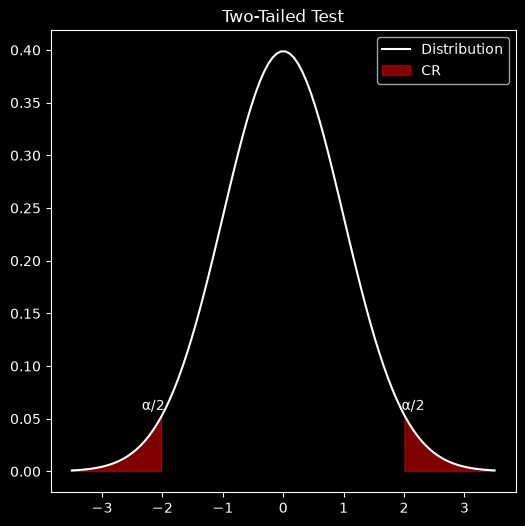

In [68]:
# Plot the normal distribution
plt.plot(x, norm.pdf(x, mu, sigma), color='white')

# Critical values for both tails
low = norm.ppf(alpha / 2)
high = norm.ppf(1 - alpha / 2)

# Add the critical region (CR)
plt.fill_between(x, norm.pdf(x, mu, sigma), where=(x <= low) | (x >= high), color='red', alpha=0.5)

# Add annotations
plt.text(low, norm.pdf(low, mu, sigma), 'α/2', ha='right')
plt.text(high, norm.pdf(high, mu, sigma), 'α/2', ha='left')

# Add title and legend
plt.title('Two-Tailed Test')
plt.legend(['Distribution', 'CR'])

# Display the chart
plt.show()

## **One-Tailed Test**

Used to verify whether the parameter is significantly smaller or larger than the value $\theta_0$. The entire critical region lies in a single tail, with area $\alpha$.

In a left-tailed test, the alternative hypothesis is

$H_1: \theta < \theta_0$

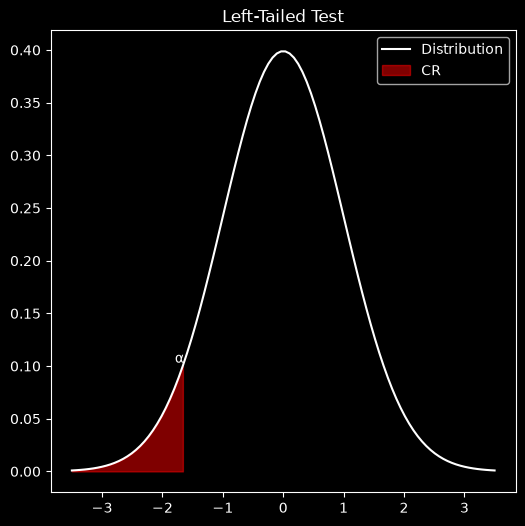

In [69]:
# Plot the normal distribution
plt.plot(x, norm.pdf(x, mu, sigma), color='white')

# Add the critical region (CR) in the left tail
low = norm.ppf(alpha)
plt.fill_between(x, norm.pdf(x, mu, sigma), where=(x <= low), color='red', alpha=0.5)

# Add annotation
plt.text(low, norm.pdf(low, mu, sigma), 'α', ha='right')

# Add title and legend
plt.title('Left-Tailed Test')
plt.legend(['Distribution', 'CR'])

# Display the chart
plt.show()

In a right-tailed test, the alternative hypothesis is

$H_1: \theta > \theta_0$

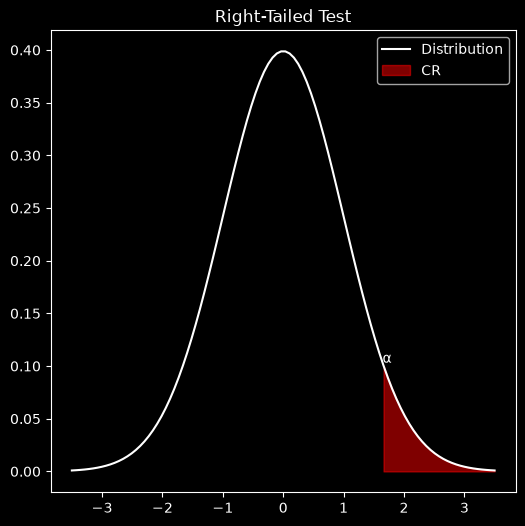

In [70]:
# Plot the normal distribution
plt.plot(x, norm.pdf(x, mu, sigma), color='white')

# Add the critical region (CR) in the right tail
high = norm.ppf(1 - alpha)
plt.fill_between(x, norm.pdf(x, mu, sigma), where=(x >= high), color='red', alpha=0.5)

# Add annotation
plt.text(high, norm.pdf(high, mu, sigma), 'α', ha='left')

# Add title and legend
plt.title('Right-Tailed Test')
plt.legend(['Distribution', 'CR'])

# Display the chart
plt.show()

## **Types of Errors**

Once both hypotheses are defined, we use a random sample to reject or fail to reject $H_0$, which can lead to two types of error:

- `Type I Error:` rejecting the null hypothesis when it is true.

$P(E_I) = P(\text{reject } H_0 \text{ | } H_0 \text{ is true}) = \alpha$

- `Type II Error:` failing to reject the null hypothesis when it is false.

$P(E_{II}) = P(\text{fail to reject } H_0 \text{ | } H_0 \text{ is false}) = \beta$

`NOTE:` *Table 7.1 of the textbook summarizes the four possible outcomes: failing to reject a true $H_0$ is a correct decision ($1 - \alpha$), rejecting a false $H_0$ is also correct ($1 - \beta$, the `power of the test`), and the other two cases are Type I ($\alpha$) and Type II ($\beta$) errors.*

## **Procedure for Conducting a Hypothesis Test**

Step by step:
1. Choose the appropriate statistical test for the research objective.
2. State the null hypothesis $H_0$ and the alternative hypothesis $H_1$.
3. Set the significance level $\alpha$.
4. Calculate the observed value of the test statistic based on the sample.
5. Determine the critical region of the test as a function of $\alpha$.
6. Make the decision: if the test statistic falls in the critical region, reject $H_0$; otherwise, fail to reject $H_0$.

In practice, statistical software computes the `p-value`, which is the probability associated with the test statistic calculated from the sample. It indicates the smallest significance level that would lead to rejecting $H_0$. Thus, steps 5 and 6 become:

5. Determine the p-value associated with the statistic calculated in step 4.
6. Make the decision: if $P \leq \alpha$, reject $H_0$; otherwise, fail to reject $H_0$.

Since steps 5 and 6 repeat across all tests, let's create a helper function that formats the decision from the p-value.

In [71]:
def decision(p_value, alpha):
    if p_value <= alpha:
        return f"P = {np.round(p_value, 4)} <= {alpha}: reject H0"
    return f"P = {np.round(p_value, 4)} > {alpha}: fail to reject H0"

And another helper function to plot the distribution of the test statistic showing the critical region (CR), the non-rejection region (NR), and the calculated value, just like the figures in the textbook.

In [72]:
def critical_region(distribution, critical_val, statistic, side="two-tailed", title="", x_label="Statistic"):

    # Chart range, including the calculated value
    start = min(distribution.ppf(0.0005), statistic - 0.5)
    end = max(distribution.ppf(0.9995), statistic + 0.5)
    x = np.linspace(start, end, 500)
    y = distribution.pdf(x)

    # Critical region according to the test type
    if side == "two-tailed":
        cr = (x <= -critical_val) | (x >= critical_val)
        marks = [-critical_val, critical_val]
    elif side == "left":
        cr = x <= critical_val
        marks = [critical_val]
    else:
        cr = x >= critical_val
        marks = [critical_val]

    plt.plot(x, y, color='white')
    plt.fill_between(x, y, where=cr, color='red', alpha=0.5, label='CR')
    plt.fill_between(x, y, where=~cr, color='gray', alpha=0.3, label='NR')

    for m in marks:
        plt.axvline(m, color='red', linestyle=':', linewidth=1)
        plt.text(m, 0.15 * y.max(), f' {np.round(m, 3)}', ha='left', color='red')

    plt.axvline(statistic, color='yellow', linestyle='--', label=f'Calculated = {np.round(statistic, 3)}')
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel('Density')
    plt.legend()

    # Display the chart
    plt.show()

## **Parametric Tests**

Hypothesis tests are divided into parametric and non-parametric tests (the latter are covered in Module 08).

* `Parametric tests:` hypotheses are formulated about population parameters, such as the mean $\mu$, standard deviation $\sigma$, and variance $\sigma^2$.
* `Non-parametric tests:` hypotheses are formulated about qualitative or distribution-free characteristics of the population.

Parametric tests are applied to quantitative data and require strict assumptions:

1. Observations must be independent.
2. The sample must come from a population with a specific distribution, usually the normal distribution.
3. When comparing two independent means or $k$ means ($k \geq 3$), the populations must have equal variances.
4. Variables must be measured on an interval or ratio scale so that arithmetic operations are meaningful.

Therefore, before comparing means, we check `normality` (Kolmogorov-Smirnov, Shapiro-Wilk, and Shapiro-Francia) and `homogeneity of variances` (Bartlett, Cochran, Hartley, and Levene).

## **Tests for Univariate Normality**

All tests in this section share the same hypotheses:

$H_0:$ the sample comes from a population with a normal distribution $N(\mu, \sigma)$

$H_1:$ the sample does not come from a population with a normal distribution $N(\mu, \sigma)$

### **Kolmogorov-Smirnov Test**

Essentially a goodness-of-fit test: it compares the observed cumulative frequency distribution in the sample with the expected theoretical distribution (here, the normal distribution). The test statistic is the largest absolute difference between the two distributions.

$D_{cal} = \max\{|F_{exp}(X_i) - F_{obs}(X_i)|;\ |F_{exp}(X_i) - F_{obs}(X_{i-1})|\}$

We reject $H_0$ if $D_{cal} > D_c$. For $n > 35$, the critical value can be approximated by $D_c \approx \frac{1.36}{\sqrt{n}}$ ($\alpha = 5\%$).

`NOTE:` *The test loses power in small samples, so it should be used when* $n \geq 30$.

#### Example 1

Monthly production of agricultural machinery by a company over the last 36 months. Check whether the data come from a normal population, with $\alpha = 5\%$.

In [73]:
machine_production = [52, 50, 44, 50, 42, 30, 36, 34, 48, 40, 55, 40,
                      30, 36, 40, 42, 55, 44, 38, 42, 40, 38, 52, 44,
                      52, 34, 38, 44, 48, 36, 36, 55, 50, 34, 44, 42]
len(machine_production)

36

In [74]:
def kolmogorov_smirnov(data):

    data = pd.Series(data)
    n = len(data)

    # Absolute, cumulative, and observed cumulative relative frequencies
    table = data.value_counts().sort_index().to_frame("F_abs")
    table["F_cum"] = table["F_abs"].cumsum()
    table["Frel_obs"] = table["F_cum"] / n

    # Standardized values and expected cumulative frequency (normal)
    table["Z"] = (table.index - data.mean()) / data.std()
    table["Frel_exp"] = norm.cdf(table["Z"])

    # Differences with the observed frequency of the current and previous class
    table["|Fexp - Fobs(i)|"] = abs(table["Frel_exp"] - table["Frel_obs"])
    table["|Fexp - Fobs(i-1)|"] = abs(table["Frel_exp"] - table["Frel_obs"].shift(1, fill_value=0))

    d_cal = table[["|Fexp - Fobs(i)|", "|Fexp - Fobs(i-1)|"]].max().max()

    return np.round(table, 4), d_cal

In [75]:
ks_table, d_cal = kolmogorov_smirnov(machine_production)
ks_table

,F_abs,F_cum,Frel_obs,Z,Frel_exp,|Fexp - Fobs(i)|,|Fexp - Fobs(i-1)|
30,2,2,0.0556,-1.7801,0.0375,0.0180,0.0375
34,3,5,0.1389,-1.2168,0.1118,0.0270,0.0563
36,4,9,0.2500,-0.9351,0.1749,0.0751,0.0360
38,3,12,0.3333,-0.6534,0.2568,0.0766,0.0068
40,4,16,0.4444,-0.3717,0.3551,0.0894,0.0217
42,4,20,0.5556,-0.0900,0.4641,0.0914,0.0197
44,5,25,0.6944,0.1917,0.5760,0.1184,0.0205
48,2,27,0.7500,0.7551,0.7749,0.0249,0.0805
50,3,30,0.8333,1.0368,0.8501,0.0167,0.1001
52,3,33,0.9167,1.3185,0.9063,0.0103,0.0730


In [76]:
d_critical = 1.36 / np.sqrt(len(machine_production))

print(f"Calculated D: {np.round(d_cal, 3)}")
print(f"Critical D (5%): {np.round(d_critical, 3)}")

Calculated D: 0.118
Critical D (5%): 0.227


Note that $D_{cal} = 0.118$ is smaller than $D_c = 0.227$ (the textbook, using Table G, uses 0.23), so we fail to reject $H_0$: at a 95% confidence level, agricultural machinery production follows a normal distribution.

SciPy already provides this test out of the box. Since the mean and standard deviation are estimated from the sample itself, we pass those values as parameters of the normal distribution.

In [77]:
dist = stats.norm(loc=np.mean(machine_production),
                  scale=np.std(machine_production, ddof=1))

d_scipy, p_ks = stats.kstest(machine_production, dist.cdf)

print(f"D (scipy): {np.round(d_scipy, 3)}")
print(decision(p_ks, 0.05))


D (scipy): 0.118
P = 0.6503 > 0.05: fail to reject H0


`NOTE:` *When* $\mu$ *and* $\sigma$ *are estimated from the sample, the classical K-S p-value is conservative. SPSS applies the Lilliefors correction, so p-values may differ slightly, though the decision remains the same.*

See the comparison between the observed and expected cumulative distributions.

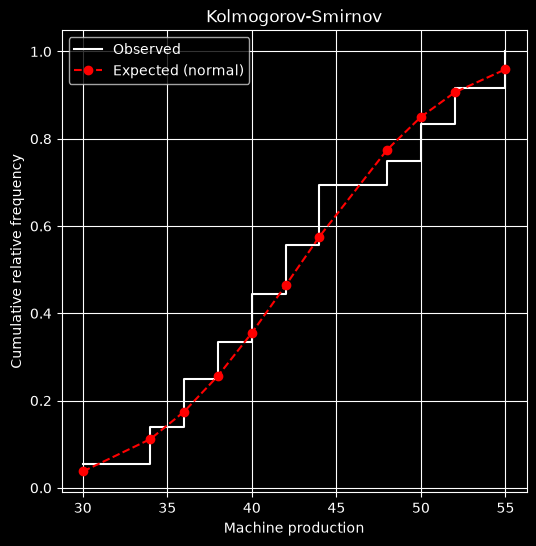

In [78]:
plt.step(ks_table.index, ks_table["Frel_obs"], where='post', color='white', label='Observed')
plt.plot(ks_table.index, ks_table["Frel_exp"], 'o--', color='red', label='Expected (normal)')
plt.xlabel('Machine production')
plt.ylabel('Cumulative relative frequency')
plt.title('Kolmogorov-Smirnov')
plt.legend()
plt.grid(True)

# Display the chart
plt.show()

### **Shapiro-Wilk Test**

Alternative to K-S for small samples ($n < 30$), applicable for $4 \leq n \leq 2000$.

$W_{cal} = \frac{b^2}{\sum_{i=1}^{n}(X_i - \overline{X})^2}$, where $b = \sum_{i=1}^{n/2}a_{i,n}\cdot(X_{(n-i+1)} - X_{(i)})$

with $X_{(i)}$ being the $i$-th ordered observation and $a_{i,n}$ tabulated constants (Table H2 in the textbook). Small values of $W$ indicate lack of normality, so we reject $H_0$ if $W_{cal} < W_c$ (left-tailed test).

#### Example 2

Monthly aircraft production by an aerospace company over the last 24 months, with $\alpha = 1\%$.

In [79]:
aircraft_production = [28, 32, 46, 24, 22, 18, 20, 34, 30, 24, 31, 29,
                       15, 19, 23, 25, 28, 30, 32, 36, 39, 16, 23, 36]

w_cal, p_sw = stats.shapiro(aircraft_production)

print(f"Calculated W: {np.round(w_cal, 3)}")
print(decision(p_sw, 0.01))

Calculated W: 0.978
P = 0.8565 > 0.01: fail to reject H0


Note that $W_{cal} = 0.978$ is greater than the critical value $W_c = 0.884$ ($n = 24$, $\alpha = 1\%$, Table H1 in the textbook) and the p-value is much greater than 1%, so we fail to reject $H_0$: aircraft production follows a normal distribution.

### **Shapiro-Francia Test**

A simplified version of Shapiro-Wilk, equally robust, applicable for $5 \leq n \leq 5000$. The coefficients $a_{i,n}$ are replaced by the approximate expected values of the ordered observations:

$W'_{cal} = \frac{\left[\sum_{i=1}^{n}m_i\cdot X_{(i)}\right]^2}{\sum_{i=1}^{n}m_i^2\cdot\sum_{i=1}^{n}(X_i - \overline{X})^2}$, with $m_i = \Phi^{-1}\left(\frac{i}{n+1}\right)$

where $\Phi^{-1}$ is the inverse standard normal CDF. Just like in Shapiro-Wilk, we reject $H_0$ if $W'_{cal} < W'_c$.

`NOTE:` *SciPy does not include Shapiro-Francia, so we will implement it directly. The p-value uses Royston's (1993) approximation, the same used by Stata's* `sfrancia` *command.*

In [80]:
def shapiro_francia(data):

    x = np.sort(np.array(data, dtype=float))
    n = len(x)

    # Approximate expected values of the ordered observations
    m = norm.ppf(np.arange(1, n + 1) / (n + 1))

    w = np.sum(m * x)**2 / (np.sum(m**2) * np.sum((x - x.mean())**2))

    # p-value via Royston's approximation
    u = np.log(n)
    v = np.log(u)
    mean = -1.2725 + 1.0521 * (v - u)
    std = 1.0308 - 0.26758 * (v + 2 / u)
    z = (np.log(1 - w) - mean) / std

    return w, 1 - norm.cdf(z)

#### Example 3

Daily bicycle production by a company over the last 60 days, with $\alpha = 5\%$.

In [81]:
bicycle_production = [85, 70, 74, 49, 67, 88, 80, 91, 57, 63, 66, 60,
                      72, 81, 73, 80, 55, 54, 93, 77, 80, 64, 60, 63,
                      67, 54, 59, 78, 73, 84, 91, 57, 59, 64, 68, 67,
                      70, 76, 78, 75, 80, 81, 70, 77, 65, 63, 59, 60,
                      61, 74, 76, 81, 79, 78, 60, 68, 76, 71, 72, 84]

w_sf, p_sf = shapiro_francia(bicycle_production)

print(f"Calculated W': {np.round(w_sf, 3)}")
print(decision(p_sf, 0.05))

Calculated W': 0.989
P = 0.7766 > 0.05: fail to reject H0


Note that $W'_{cal} = 0.989$ is greater than the critical value $W'_c = 0.9625$ ($n = 60$, $\alpha = 5\%$), so we fail to reject $H_0$: bicycle production follows a normal distribution.

A common visual complement to normality tests is the `Q-Q plot`: if the points lie close to the straight line, the data are consistent with a normal distribution.

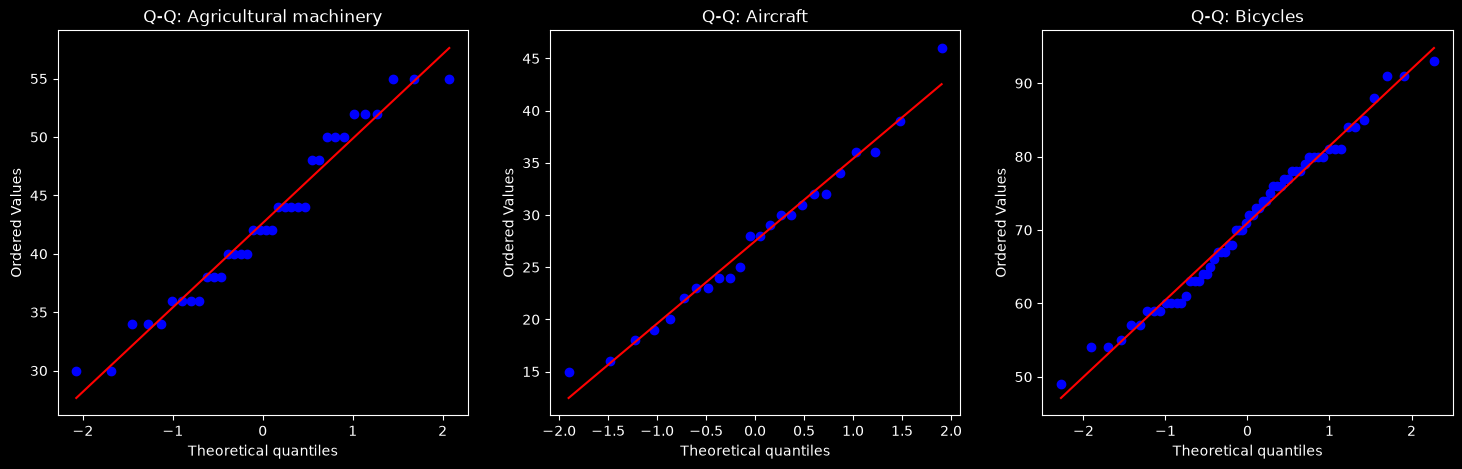

In [82]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

stats.probplot(machine_production, dist='norm', plot=ax[0])
stats.probplot(aircraft_production, dist='norm', plot=ax[1])
stats.probplot(bicycle_production, dist='norm', plot=ax[2])

ax[0].set_title('Q-Q: Agricultural machinery')
ax[1].set_title('Q-Q: Aircraft')
ax[2].set_title('Q-Q: Bicycles')

# Display the chart
plt.show()

## **Tests for Homogeneity of Variances**

One of the requirements for comparing $k$ population means is that the population variances are homogeneous. In the tests in this section:

$H_0: \sigma_1^2 = \sigma_2^2 = \cdots = \sigma_k^2$

$H_1: \exists_{(i,j)}\ \sigma_i^2 \neq \sigma_j^2,\ (i, j = 1, ..., k)$

#### Example 4

A supermarket owner wants to study the number of customers served per day across three stores over two weeks ($\alpha = 5\%$). The same dataset will be used for all homogeneity of variance tests.

In [83]:
customers = pd.DataFrame({
    "Store 1": [620, 630, 610, 650, 585, 590, 630, 644, 595, 603, 570, 605, 622, 578],
    "Store 2": [710, 780, 810, 755, 699, 680, 710, 850, 844, 730, 645, 688, 718, 702],
    "Store 3": [924, 695, 854, 802, 931, 924, 847, 800, 769, 863, 901, 888, 757, 712]
})

customers.agg(["mean", "std", "var"]).round(2)

,Store 1,Store 2,Store 3
mean,609.43,737.21,833.36
std,24.41,62.25,78.91
var,595.65,3874.64,6227.48


### **Bartlett's $\chi^2$ Test**

The original test for homogeneity of variances, though it is very sensitive to departures from normality.

$q = (N - k)\cdot\ln(S_p^2) - \sum_{i=1}^{k}(n_i - 1)\cdot\ln(S_i^2)$, with $S_p^2 = \frac{\sum_{i=1}^{k}(n_i - 1)\cdot S_i^2}{N - k}$

$c = 1 + \frac{1}{3\cdot(k-1)}\cdot\left(\sum_{i=1}^{k}\frac{1}{n_i - 1} - \frac{1}{N - k}\right)$

$B_{cal} = \frac{q}{c} \sim \chi^2_{k-1}$

We reject $H_0$ if $B_{cal} > \chi^2_c$.

In [84]:
def bartlett(*groups):

    k = len(groups)
    n = np.array([len(g) for g in groups])
    s2 = np.array([np.var(g, ddof=1) for g in groups])
    N = n.sum()

    # Pooled variance
    s2_p = np.sum((n - 1) * s2) / (N - k)

    q = (N - k) * np.log(s2_p) - np.sum((n - 1) * np.log(s2))
    c = 1 + (1 / (3 * (k - 1))) * (np.sum(1 / (n - 1)) - 1 / (N - k))

    return q / c

In [85]:
b_cal = bartlett(customers["Store 1"], customers["Store 2"], customers["Store 3"])
chi2_critical = chi2.ppf(1 - 0.05, df=3 - 1)

print(f"Calculated B: {np.round(b_cal, 3)}")
print(f"Critical Chi-square (5%, 2 df): {np.round(chi2_critical, 3)}")

# Verifying with scipy
b_scipy, p_bartlett = stats.bartlett(
    customers["Store 1"].astype(float),
    customers["Store 2"].astype(float),
    customers["Store 3"].astype(float)
)
print(decision(p_bartlett, 0.05))

Calculated B: 14.443
Critical Chi-square (5%, 2 df): 5.991
P = 0.0007 <= 0.05: reject H0


Note that $B_{cal} = 14.443$ is greater than $\chi^2_c = 5.991$, so we reject $H_0$: at a 95% confidence level, the variance of at least one store differs from the others.

`NOTE:` *The textbook obtains $B_{cal} = 14.567$ because it uses $c = 1.0256$. By the formula for $c$, the exact value is $c = 1 + \frac{1}{6}\cdot\left(\frac{3}{13} - \frac{1}{39}\right) = 1.0342$, which yields 14.443—the same value returned by* `stats.bartlett`*. The conclusion does not change.*

### **Cochran's C Test**

Compares the group with the largest variance against the others and requires normally distributed data.

$C_{cal} = \frac{S_{\max}^2}{\sum_{i=1}^{k}S_i^2}$

If all variances are equal, $C_{cal} = 1/k$. The more $S_{\max}^2$ stands out from the rest, the closer $C_{cal}$ approaches 1. We reject $H_0$ if $C_{cal} > C_c$.

`NOTE:` *The textbook takes $C_c$ from Table M. Here we use the exact relationship with the F-distribution for equal-sized groups* $n$:

$C_c = \frac{1}{1 + \frac{k-1}{F_c}}$, with $F_c = F_{n-1,\ (n-1)(k-1),\ \alpha/k}$

In [86]:
variances = customers.var()
k = len(variances)
n = len(customers)

c_cal = variances.max() / variances.sum()

# Critical value via the F-distribution
f_c = f.ppf(1 - 0.05 / k, n - 1, (n - 1) * (k - 1))
c_critical = 1 / (1 + (k - 1) / f_c)

print(f"Group with largest variance: {variances.idxmax()}")
print(f"Calculated C: {np.round(c_cal, 3)}")
print(f"Critical C (5%): {np.round(c_critical, 3)}")

Group with largest variance: Store 3
Calculated C: 0.582
Critical C (5%): 0.57


Note that $C_{cal} = 0.582$ is greater than $C_c = 0.570$ (Table M in the textbook gives 0.575), so we reject $H_0$: the variance of Store 3 differs from the others.

### **Hartley's $F_{\max}$ Test**

Ratio between the largest and smallest variances. Assumes all groups have the same number of observations.

$F_{\max,cal} = \frac{S_{\max}^2}{S_{\min}^2}$

If the variances are equal, $F_{\max} = 1$. We reject $H_0$ if $F_{\max,cal} > F_{\max,c}$.

In [87]:
f_max_cal = variances.max() / variances.min()

# Critical value from Table N in the textbook (k = 3, df = 13, alpha = 5%)
f_max_critical = 3.953

print(f"Largest variance: {variances.idxmax()} | Smallest variance: {variances.idxmin()}")
print(f"Calculated Fmax: {np.round(f_max_cal, 2)}")
print(f"Critical Fmax (5%): {f_max_critical}")

Largest variance: Store 3 | Smallest variance: Store 1
Calculated Fmax: 10.45
Critical Fmax (5%): 3.953


Note that $F_{\max,cal} = 10.45$ is much greater than $F_{\max,c} = 3.953$, so we reject $H_0$: the variance of Store 3 differs from the variance of Store 1.

`NOTE:` *The $F_{\max}$ distribution is not built into SciPy, so the critical value was taken from Table N of the textbook.*

### **Levene's F Test**

Less sensitive to departures from normality and considered the most robust among homogeneity of variance tests. Essentially, it performs an ANOVA on the absolute deviations of each observation from its group mean, $Z_{ij} = |X_{ij} - \overline{X}_i|$.

$F_{cal} = \frac{(N-k)}{(k-1)}\cdot\frac{\sum_{i=1}^{k}n_i\cdot(\overline{Z}_i - \overline{Z})^2}{\sum_{i=1}^{k}\sum_{j=1}^{n_i}(Z_{ij} - \overline{Z}_i)^2} \sim F_{k-1,\ N-k}$

We reject $H_0$ if $F_{cal} > F_c$.

In [88]:
def levene(*groups):

    k = len(groups)
    z = [np.abs(np.array(g) - np.mean(g)) for g in groups]  # Absolute deviations from the mean
    n = np.array([len(g) for g in groups])
    N = n.sum()

    z_means = np.array([zi.mean() for zi in z])
    z_overall = np.concatenate(z).mean()

    numerator = np.sum(n * (z_means - z_overall)**2)
    denominator = np.sum([np.sum((zi - zi.mean())**2) for zi in z])

    f_cal = (N - k) / (k - 1) * numerator / denominator
    p_value = 1 - f.cdf(f_cal, k - 1, N - k)

    return f_cal, p_value

In [89]:
f_levene, p_levene = levene(customers["Store 1"], customers["Store 2"], customers["Store 3"])
f_critical = f.ppf(1 - 0.05, 3 - 1, 42 - 3)

print(f"Calculated F: {np.round(f_levene, 3)}")
print(f"Critical F (5%; 2 and 39 df): {np.round(f_critical, 2)}")
print(decision(p_levene, 0.05))

Calculated F: 8.427
Critical F (5%; 2 and 39 df): 3.24
P = 0.0009 <= 0.05: reject H0


In [90]:
# Verifying with scipy (center='mean' reproduces the textbook version)
stats.levene(customers["Store 1"], customers["Store 2"], customers["Store 3"], center='mean')

LeveneResult(statistic=np.float64(8.426665687474399), pvalue=np.float64(0.0009084535848988527))

Note that $F_{cal} = 8.427$ is greater than $F_c = 3.24$, so we reject $H_0$: the three stores do not have homogeneous variances. All four tests reached the same conclusion.

`NOTE:` *By default,* `stats.levene` *uses the median (`center='median'`), a version proposed by Brown and Forsythe (1974) that is even more robust. To match the textbook and SPSS, use `center='mean'`.*

## **Tests for a Single Population Mean**

The goal is to test whether a population mean equals a specific value $\mu_0$:

$H_0: \mu = \mu_0$

$H_1: \mu \neq \mu_0$ (or $\mu < \mu_0$, or $\mu > \mu_0$, for one-tailed tests)

For a one-tailed test, the p-value is $P = P_1$; for a two-tailed test, it is doubled, $P = 2\cdot P_1$.

### **Z-Test (Known $\sigma$)**

Used when the sample comes from a normal population with a known standard deviation $\sigma$. If the distribution is unknown, the sample must be large ($n > 30$), since the Central Limit Theorem guarantees that the sample mean approximates a normal distribution.

$Z_{cal} = \frac{\overline{X} - \mu_0}{\sigma / \sqrt{n}} \sim N(0, 1)$

In [91]:
def z_test(sample_mean, mu_0, sigma, n, alternative="two-tailed"):

    z_cal = (sample_mean - mu_0) / (sigma / np.sqrt(n))

    if alternative == "left":
        p_value = norm.cdf(z_cal)
    elif alternative == "right":
        p_value = 1 - norm.cdf(z_cal)
    else:
        p_value = 2 * (1 - norm.cdf(abs(z_cal)))

    return z_cal, p_value

#### Example 8

A cereal manufacturer claims that each serving contains at least 4.2 g of fiber, with a standard deviation of 1 g. A health agency collected 42 servings and found a mean of 3.9 g. At $\alpha = 5\%$, is there evidence to reject the claim?

$H_0: \mu \geq 4.2$ g and $H_1: \mu < 4.2$ g (left-tailed)

In [92]:
z_cal, p_z = z_test(sample_mean=3.9, mu_0=4.2, sigma=1, n=42, alternative="left")

print(f"Calculated Z: {np.round(z_cal, 2)}")
print(f"Critical Z (5%, left-tailed): {np.round(norm.ppf(0.05), 3)}")
print(decision(p_z, 0.05))

Calculated Z: -1.94
Critical Z (5%, left-tailed): -1.645
P = 0.0259 <= 0.05: reject H0


Note that $Z_{cal} = -1.94$ falls in the critical region ($Z_{cal} < -1.645$) and the p-value is 0.026, so we reject $H_0$: at a 95% confidence level, the average amount of fiber is less than 4.2 g.

### **One-Sample Student's t-Test (Unknown $\sigma$)**

When $\sigma$ is unknown, it is estimated by the sample standard deviation $S$, and the test statistic follows a Student's $t$-distribution with $n - 1$ degrees of freedom.

$T_{cal} = \frac{\overline{X} - \mu_0}{S / \sqrt{n}} \sim t_{n-1}$

In [93]:
def one_sample_t_test(sample_mean, mu_0, s, n, alternative="two-tailed"):

    t_cal = (sample_mean - mu_0) / (s / np.sqrt(n))
    df = n - 1

    if alternative == "left":
        p_value = t.cdf(t_cal, df)
    elif alternative == "right":
        p_value = 1 - t.cdf(t_cal, df)
    else:
        p_value = 2 * (1 - t.cdf(abs(t_cal), df))

    return t_cal, p_value

#### Example 9

The average processing time for a task was 18 minutes. After process changes, a sample of 25 tasks had a mean of 16.808 minutes and a standard deviation of 2.733 minutes. At $\alpha = 1\%$, was there an improvement?

$H_0: \mu = 18$ and $H_1: \mu < 18$ (left-tailed)

In [94]:
t_cal, p_t = one_sample_t_test(sample_mean=16.808, mu_0=18, s=2.733, n=25, alternative="left")

print(f"Calculated T: {np.round(t_cal, 2)}")
print(f"Critical t (1%, 24 df, left-tailed): {np.round(t.ppf(0.01, 24), 3)}")
print(decision(p_t, 0.01))

Calculated T: -2.18
Critical t (1%, 24 df, left-tailed): -2.492
P = 0.0196 > 0.01: fail to reject H0


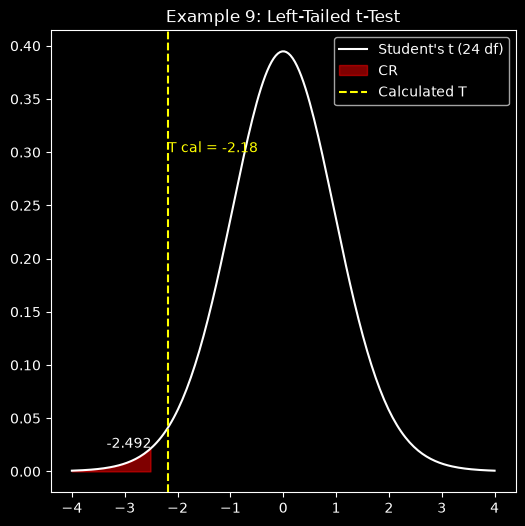

In [95]:
# Critical region for Example 9
df = 24
x = np.linspace(-4, 4, 200)
t_critical = t.ppf(0.01, df)

plt.plot(x, t.pdf(x, df), color='white')
plt.fill_between(x, t.pdf(x, df), where=(x <= t_critical), color='red', alpha=0.5)
plt.axvline(t_cal, color='yellow', linestyle='--')

plt.text(t_critical, t.pdf(t_critical, df), f'{np.round(t_critical, 3)}', ha='right')
plt.text(t_cal, 0.3, f'T cal = {np.round(t_cal, 2)}', ha='left', color='yellow')

plt.title('Example 9: Left-Tailed t-Test')
plt.legend(["Student's t (24 df)", 'CR', 'Calculated T'])

# Display the chart
plt.show()

Note that $T_{cal} = -2.18$ does not reach the critical region ($t_c = -2.492$) and the p-value (0.0196) is greater than 1%, so we fail to reject $H_0$: at a 99% confidence level, there was no improvement in average processing time.

`NOTE:` *With raw data, the same test can be run directly using* `stats.ttest_1samp(data, popmean=18, alternative='less')`.

## **Independent Two-Sample t-Test**

Compares the means of two independent random samples when the population variance is unknown.

$H_0: \mu_1 = \mu_2$

$H_1: \mu_1 \neq \mu_2$

The calculation depends on whether the variances are homogeneous or not, so we first apply Levene's test.

* `Unequal variances:`

$T_{cal} = \frac{\overline{X}_1 - \overline{X}_2}{\sqrt{\frac{S_1^2}{n_1} + \frac{S_2^2}{n_2}}}$, with $\nu = \frac{\left(\frac{S_1^2}{n_1} + \frac{S_2^2}{n_2}\right)^2}{\frac{(S_1^2/n_1)^2}{n_1 - 1} + \frac{(S_2^2/n_2)^2}{n_2 - 1}}$ degrees of freedom

* `Equal (homogeneous) variances:`

$T_{cal} = \frac{\overline{X}_1 - \overline{X}_2}{S_p\cdot\sqrt{\frac{1}{n_1} + \frac{1}{n_2}}}$, with $S_p = \sqrt{\frac{(n_1 - 1)\cdot S_1^2 + (n_2 - 1)\cdot S_2^2}{n_1 + n_2 - 2}}$ and $\nu = n_1 + n_2 - 2$

#### Example 10

A quality engineer suspects that the manufacturing time of a plastic product depends on the raw material supplier. Thirty observations were collected from each supplier ($\alpha = 5\%$).

In [96]:
supplier_1 = [22.8, 23.4, 26.2, 24.3, 22.0, 24.8, 26.7, 25.1, 23.1, 22.8,
              25.6, 25.1, 24.3, 24.2, 22.8, 23.2, 24.7, 26.5, 24.5, 23.6,
              23.9, 22.8, 25.4, 26.7, 22.9, 23.5, 23.8, 24.6, 26.3, 22.7]

supplier_2 = [26.8, 29.3, 28.4, 25.6, 29.4, 27.2, 27.6, 26.8, 25.4, 28.6,
              29.7, 27.2, 27.9, 28.4, 26.0, 26.8, 27.5, 28.5, 27.3, 29.1,
              29.2, 25.7, 28.4, 28.6, 27.9, 27.4, 26.7, 26.8, 25.6, 26.1]

print(f"Supplier 1: mean = {np.round(np.mean(supplier_1), 3)} | variance = {np.round(np.var(supplier_1, ddof=1), 3)}")
print(f"Supplier 2: mean = {np.round(np.mean(supplier_2), 3)} | variance = {np.round(np.var(supplier_2, ddof=1), 3)}")

Supplier 1: mean = 24.277 | variance = 1.81
Supplier 2: mean = 27.53 | variance = 1.559


In [97]:
# Homogeneity of variances
_, p_levene_10 = stats.levene(supplier_1, supplier_2, center='mean')
print(f"Levene: {decision(p_levene_10, 0.05)}")

Levene: P = 0.6943 > 0.05: fail to reject H0


In [98]:
t_cal_10, p_t_10 = stats.ttest_ind(supplier_1, supplier_2, equal_var=True)

print(f"Calculated T: {np.round(t_cal_10, 3)}")
print(f"Critical t (5%, 58 df, two-tailed): ±{np.round(t.ppf(1 - 0.05/2, 58), 3)}")
print(decision(p_t_10, 0.05))

Calculated T: -9.708
Critical t (5%, 58 df, two-tailed): ±2.002
P = 0.0 <= 0.05: reject H0


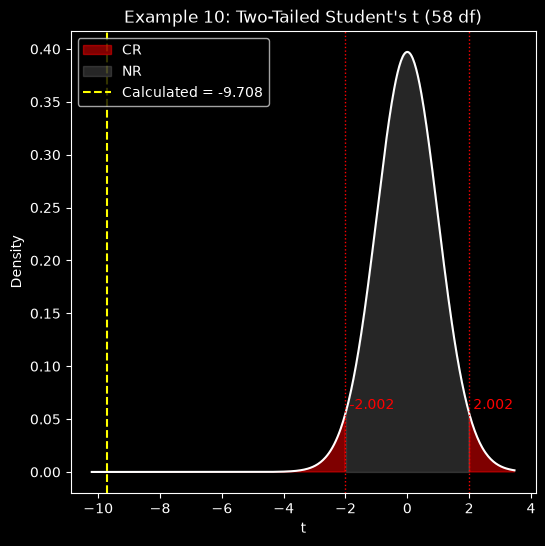

In [99]:
# Critical region for Example 10
critical_region(t(58), t.ppf(1 - 0.05/2, 58), t_cal_10, side="two-tailed",
                title="Example 10: Two-Tailed Student's t (58 df)", x_label='t')

Note that the variances are homogeneous (Levene, P = 0.694) and $T_{cal} = -9.708$ lies well below $-t_c = -2.002$, so we reject $H_0$: at a 95% confidence level, average manufacturing time differs by supplier (Supplier 2 is slower).

`NOTE:` *In the textbook, the values 1.810 and 1.559 are printed as* $S_1$ *and* $S_2$*, but they are actually the variances* $S_1^2$ *and* $S_2^2$*, as shown by the calculation of* $S_p$*. If the variances were not homogeneous, we would use* `equal_var=False` *(Welch's t-test).*

## **Paired Two-Sample t-Test**

Used when the two samples are related, such as before-and-after measurements on the same subject. We compute the difference for each pair, $d_i = X_{\text{before},i} - X_{\text{after},i}$, and test whether the population mean of the differences is zero.

$H_0: \mu_d = 0$

$H_1: \mu_d \neq 0$

$T_{cal} = \frac{\overline{d}}{S_d / \sqrt{n}} \sim t_{n-1}$, with $\overline{d} = \frac{\sum_{i=1}^{n}d_i}{n}$ and $S_d = \sqrt{\frac{\sum_{i=1}^{n}(d_i - \overline{d})^2}{n-1}}$

#### Example 10

A quality engineer suspects that the manufacturing time of a plastic product depends on the raw material supplier. Thirty observations were collected from each supplier ($\alpha = 5\%$).

In [100]:
supplier_1 = [22.8, 23.4, 26.2, 24.3, 22.0, 24.8, 26.7, 25.1, 23.1, 22.8,
              25.6, 25.1, 24.3, 24.2, 22.8, 23.2, 24.7, 26.5, 24.5, 23.6,
              23.9, 22.8, 25.4, 26.7, 22.9, 23.5, 23.8, 24.6, 26.3, 22.7]

supplier_2 = [26.8, 29.3, 28.4, 25.6, 29.4, 27.2, 27.6, 26.8, 25.4, 28.6,
              29.7, 27.2, 27.9, 28.4, 26.0, 26.8, 27.5, 28.5, 27.3, 29.1,
              29.2, 25.7, 28.4, 28.6, 27.9, 27.4, 26.7, 26.8, 25.6, 26.1]

print(f"Supplier 1: mean = {np.round(np.mean(supplier_1), 3)} | variance = {np.round(np.var(supplier_1, ddof=1), 3)}")
print(f"Supplier 2: mean = {np.round(np.mean(supplier_2), 3)} | variance = {np.round(np.var(supplier_2, ddof=1), 3)}")

Supplier 1: mean = 24.277 | variance = 1.81
Supplier 2: mean = 27.53 | variance = 1.559


In [101]:
# Homogeneity of variances
_, p_levene_10 = stats.levene(supplier_1, supplier_2, center='mean')
print(f"Levene: {decision(p_levene_10, 0.05)}")

Levene: P = 0.6943 > 0.05: fail to reject H0


In [102]:
t_cal_10, p_t_10 = stats.ttest_ind(supplier_1, supplier_2, equal_var=True)

print(f"Calculated T: {np.round(t_cal_10, 3)}")
print(f"Critical t (5%, 58 df, two-tailed): ±{np.round(t.ppf(1 - 0.05/2, 58), 3)}")
print(decision(p_t_10, 0.05))

Calculated T: -9.708
Critical t (5%, 58 df, two-tailed): ±2.002
P = 0.0 <= 0.05: reject H0


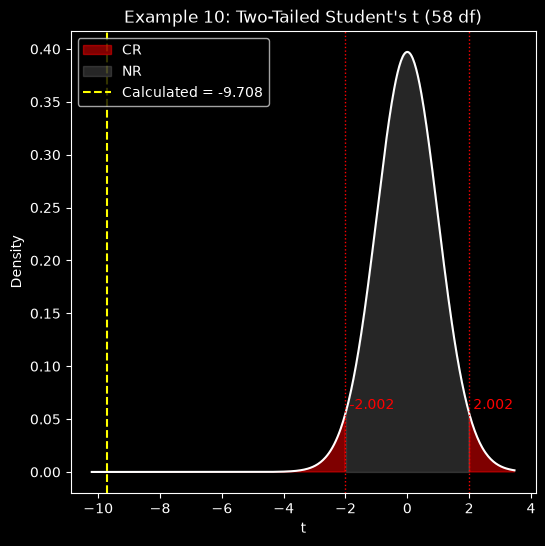

In [103]:
# Critical region for Example 10
critical_region(t(58), t.ppf(1 - 0.05/2, 58), t_cal_10, side="two-tailed",
                title="Example 10: Two-Tailed Student's t (58 df)", x_label='t')

Note that the variances are homogeneous (Levene, P = 0.694) and $T_{cal} = -9.708$ lies well below $-t_c = -2.002$, so we reject $H_0$: at a 95% confidence level, average manufacturing time differs by supplier (Supplier 2 is slower).

`NOTE:` *In the textbook, the values 1.810 and 1.559 are printed as* $S_1$ *and* $S_2$*, but they are actually the variances* $S_1^2$ *and* $S_2^2$*, as shown by the calculation of* $S_p$*. If the variances were not homogeneous, we would use* `equal_var=False` *(Welch's t-test).*

## **Paired Two-Sample t-Test**

Used when the two samples are related, such as before-and-after measurements on the same subject. We compute the difference for each pair, $d_i = X_{\text{before},i} - X_{\text{after},i}$, and test whether the population mean of the differences is zero.

$H_0: \mu_d = 0$

$H_1: \mu_d \neq 0$

$T_{cal} = \frac{\overline{d}}{S_d / \sqrt{n}} \sim t_{n-1}$, with $\overline{d} = \frac{\sum_{i=1}^{n}d_i}{n}$ and $S_d = \sqrt{\frac{\sum_{i=1}^{n}(d_i - \overline{d})^2}{n-1}}$

#### Example 11

Ten machine operators were trained to perform a task faster. Each operator's time was measured before and after training ($\alpha = 5\%$).

In [104]:
operators = pd.DataFrame({
    "Before": [3.2, 3.6, 3.4, 3.8, 3.4, 3.5, 3.7, 3.2, 3.5, 3.9],
    "After": [3.0, 3.3, 3.5, 3.6, 3.4, 3.3, 3.4, 3.0, 3.2, 3.6]
})

# Difference for each pair
operators["d"] = np.round(operators["Before"] - operators["After"], 2)

print(f"Mean of differences: {np.round(operators['d'].mean(), 2)}")
print(f"Standard deviation of differences: {np.round(operators['d'].std(), 3)}")
operators.T

Mean of differences: 0.19
Standard deviation of differences: 0.137


,0,1,2,3,4,5,6,7,8,9
Before,3.2,3.6,3.4,3.8,3.4,3.5,3.7,3.2,3.5,3.9
After,3.0,3.3,3.5,3.6,3.4,3.3,3.4,3.0,3.2,3.6
d,0.2,0.3,-0.1,0.2,0.0,0.2,0.3,0.2,0.3,0.3


In [105]:
t_cal_11, p_t_11 = stats.ttest_rel(operators["Before"], operators["After"])

print(f"Calculated T: {np.round(t_cal_11, 3)}")
print(f"Critical t (5%, 9 df, two-tailed): ±{np.round(t.ppf(1 - 0.05/2, 9), 3)}")
print(decision(p_t_11, 0.05))

Calculated T: 4.385
Critical t (5%, 9 df, two-tailed): ±2.262
P = 0.0018 <= 0.05: reject H0


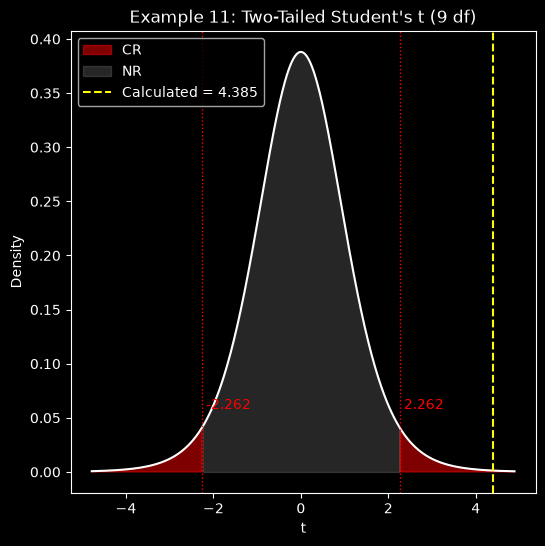

In [106]:
# Critical region for Example 11
critical_region(t(9), t.ppf(1 - 0.05/2, 9), t_cal_11, side="two-tailed",
                title="Example 11: Two-Tailed Student's t (9 df)", x_label='t')

Note that $T_{cal} = 4.385$ is greater than $t_c = 2.262$, so we reject $H_0$: at a 95% confidence level, training changed the operators' task time. Since the mean of the differences is positive ($\overline{d} = 0.19$), the time decreased.

## **ANOVA: Comparing Means of More Than Two Populations**

Analysis of Variance (ANOVA) compares the means of three or more populations using sample variances. The goal is to determine whether the differences among sample means indicate true differences between the populations or are merely the result of sampling variability.

Assumptions:
1. Samples are independent of each other.
2. Data from each population follow a normal distribution.
3. Population variances are homogeneous.

### **One-Way ANOVA**

An extension of the $t$-test to $k \geq 3$ means. It tests the effect of a single qualitative explanatory variable (`factor`) on a quantitative dependent variable.

$H_0: \mu_1 = \mu_2 = \cdots = \mu_k$

$H_1: \exists_{(i,j)}\ \mu_i \neq \mu_j,\ i \neq j$

The technique decomposes total variation into between-group variation (factor) and within-group variation (error):

* `Between groups:` $SSB = \sum_{i=1}^{k}n_i\cdot(\overline{Y}_i - \overline{Y})^2$, with $k - 1$ degrees of freedom
* `Within groups:` $SSW = \sum_{i=1}^{k}\sum_{j=1}^{n_i}(Y_{ij} - \overline{Y}_i)^2$, with $N - k$ degrees of freedom
* `Total:` $SST = SSB + SSW$, with $N - 1$ degrees of freedom

$F_{cal} = \frac{MSB}{MSW} = \frac{SSB/(k-1)}{SSW/(N-k)} \sim F_{k-1,\ N-k}$

We reject $H_0$ if $F_{cal} > F_c$.

In [107]:
def one_way_anova(*groups, names=None):

    k = len(groups)
    n = np.array([len(g) for g in groups])
    N = n.sum()
    grand_mean = np.concatenate([np.array(g, dtype=float) for g in groups]).mean()

    # Sums of squares
    ssb = np.sum([len(g) * (np.mean(g) - grand_mean)**2 for g in groups])
    ssw = np.sum([np.sum((np.array(g) - np.mean(g))**2) for g in groups])

    # Mean squares and F-statistic
    msb = ssb / (k - 1)
    msw = ssw / (N - k)
    f_cal = msb / msw
    p_value = 1 - f.cdf(f_cal, k - 1, N - k)

    # Building results table
    result = pd.DataFrame({
        "SS": [ssb, ssw, ssb + ssw],
        "df": [k - 1, N - k, N - 1],
        "MS": [msb, msw, np.nan],
        "F": [f_cal, np.nan, np.nan],
        "P-value": [p_value, np.nan, np.nan]
    }, index=["Between groups", "Within groups", "Total"])

    return result.round(4)

#### Example 12

Sucrose percentage is one of the quality measures for honey. Thirty-two samples were collected from three suppliers. Is there a difference among them ($\alpha = 5\%$)?

In [108]:
honey_supplier_1 = [0.33, 0.79, 1.24, 1.75, 0.94, 2.42, 1.97, 0.87, 0.33, 0.79, 1.24, 3.12]
honey_supplier_2 = [1.54, 1.11, 0.97, 2.57, 2.94, 3.44, 3.02, 3.55, 2.04, 1.67]
honey_supplier_3 = [1.47, 1.69, 1.55, 2.04, 2.67, 3.07, 3.33, 4.01, 1.52, 2.03]

Before running ANOVA, we check the assumptions: normality of each group (Shapiro-Wilk, since the groups are small) and homogeneity of variances (Levene).

In [109]:
for name, group in [("Supplier 1", honey_supplier_1), ("Supplier 2", honey_supplier_2), ("Supplier 3", honey_supplier_3)]:
    _, p_normal = stats.shapiro(group)
    print(f"Shapiro-Wilk {name}: {decision(p_normal, 0.05)}")

_, p_levene_12 = stats.levene(honey_supplier_1, honey_supplier_2, honey_supplier_3, center='mean')
print(f"Levene: {decision(p_levene_12, 0.05)}")

Shapiro-Wilk Supplier 1: P = 0.2462 > 0.05: fail to reject H0
Shapiro-Wilk Supplier 2: P = 0.4382 > 0.05: fail to reject H0
Shapiro-Wilk Supplier 3: P = 0.1417 > 0.05: fail to reject H0
Levene: P = 0.7164 > 0.05: fail to reject H0


In [110]:
one_way_anova(honey_supplier_1, honey_supplier_2, honey_supplier_3)

,SS,df,MS,F,P-value
Between groups,7.4492,2,3.7246,4.676,0.0174
Within groups,23.0995,29,0.7965,NaN,NaN
Total,30.5487,31,NaN,NaN,NaN


In [111]:
# Verifying with scipy
stats.f_oneway(honey_supplier_1, honey_supplier_2, honey_supplier_3)

F_onewayResult(statistic=np.float64(4.675996744085605), pvalue=np.float64(0.01737183904135484))

Note that all three groups are normal and have homogeneous variances, so ANOVA is valid. Since $F_{cal} = 4.676$ is greater than $F_c = F_{2,\ 29,\ 5\%} = 3.33$ and the p-value is below 5%, we reject $H_0$: at a 95% confidence level, at least one supplier has a different mean sucrose percentage than the others.

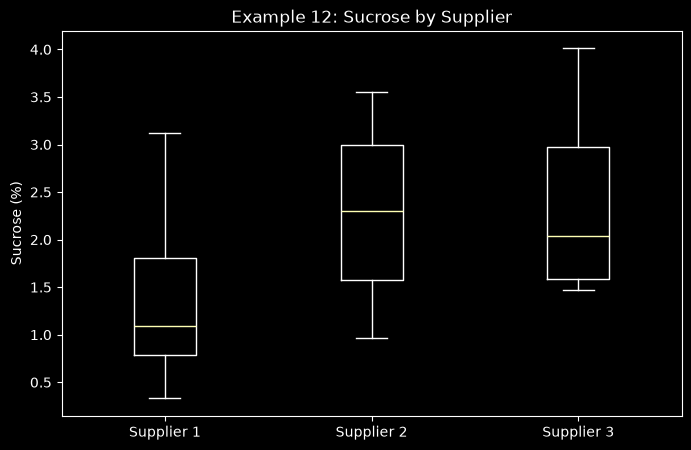

In [112]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([honey_supplier_1, honey_supplier_2, honey_supplier_3])
ax.set_xticks([1, 2, 3], ["Supplier 1", "Supplier 2", "Supplier 3"])
ax.set_ylabel('Sucrose (%)')
ax.set_title('Example 12: Sucrose by Supplier')

# Display the chart
plt.show()

### **Factorial ANOVA**

An extension of one-way ANOVA to two or more factors, with the same assumptions. In addition to the individual effect of each factor on the dependent variable, it tests the `interaction` between factors (joint effect).

#### **Two-Way ANOVA**

Let $Y_{ijk}$ be the $k$-th observation at level $i$ of factor A and level $j$ of factor B. The model is:

$Y_{ijk} = \mu + \alpha_i + \beta_j + \gamma_{ij} + e_{ijk}$

where $\alpha_i$ is the effect of factor A, $\beta_j$ is the effect of factor B, $\gamma_{ij}$ is the interaction, and $e_{ijk} \sim N(0, \sigma)$ is the error term. Three pairs of hypotheses are tested:

* `Factor A:` $H_0^A: \mu_1 = \mu_2 = \cdots = \mu_a$
* `Factor B:` $H_0^B: \mu_1 = \mu_2 = \cdots = \mu_b$
* `Interaction:` $H_0: \gamma_{ij} = 0$ (no interaction between A and B)

| Source | Sum of Squares | df | F |
|---|---|---|---|
| Factor A | $SS_A = b\cdot n\cdot\sum_{i=1}^{a}(\overline{Y}_i - \overline{Y})^2$ | $a - 1$ | $MS_A/MSE$ |
| Factor B | $SS_B = a\cdot n\cdot\sum_{j=1}^{b}(\overline{Y}_j - \overline{Y})^2$ | $b - 1$ | $MS_B/MSE$ |
| Interaction | $SS_{AB} = n\cdot\sum_{i=1}^{a}\sum_{j=1}^{b}(\overline{Y}_{ij} - \overline{Y}_i - \overline{Y}_j + \overline{Y})^2$ | $(a-1)(b-1)$ | $MS_{AB}/MSE$ |
| Error | $SSE = \sum_{i}\sum_{j}\sum_{k}(Y_{ijk} - \overline{Y}_{ij})^2$ | $(n-1)\cdot ab$ | |

`NOTE:` *These formulas apply to the balanced case (same $n$ in every cell). When cell sizes differ, sums of squares are obtained by comparing models: a term's effect is measured by how much the residual sum of squares increases when that term is removed from the model.*

In [113]:
def two_way_anova(data, y, factor_a, factor_b):

    # Models fitted via ordinary least squares
    full = ols(f"{y} ~ C({factor_a}) * C({factor_b})", data=data).fit()
    additive = ols(f"{y} ~ C({factor_a}) + C({factor_b})", data=data).fit()
    only_a = ols(f"{y} ~ C({factor_a})", data=data).fit()
    only_b = ols(f"{y} ~ C({factor_b})", data=data).fit()

    # Mean squared error of the full model
    mse = full.ssr / full.df_resid

    rows = {
        factor_a: (only_b.ssr - additive.ssr, only_b.df_resid - additive.df_resid),
        factor_b: (only_a.ssr - additive.ssr, only_a.df_resid - additive.df_resid),
        f"{factor_a} * {factor_b}": (additive.ssr - full.ssr, additive.df_resid - full.df_resid),
    }

    # Building results table
    result = pd.DataFrame(rows, index=["SS", "df"]).T
    result["MS"] = result["SS"] / result["df"]
    result["F"] = result["MS"] / mse
    result["P-value"] = 1 - f.cdf(result["F"], result["df"], full.df_resid)
    result.loc["Error"] = [full.ssr, full.df_resid, mse, np.nan, np.nan]

    return result.round(4)

#### Example 13

Travel time (min) of 24 passengers on the São Paulo–Campinas route, by bus company (1 = A, 2 = B, 3 = C) and day of the week (1 = Monday ... 7 = Sunday). Is there an effect of company, day of the week, and their interaction ($\alpha = 5\%$)?

In [114]:
trips = pd.DataFrame({
    "time": [90, 100, 72, 76, 85, 95, 79, 100, 70, 80, 85, 90,
             77, 80, 85, 74, 72, 92, 84, 80, 79, 70, 88, 84],
    "company": [2, 1, 1, 3, 2, 1, 3, 2, 1, 3, 2, 1,
                2, 1, 3, 2, 3, 1, 2, 1, 2, 3, 3, 2],
    "day_of_week": [4, 5, 6, 1, 2, 5, 1, 4, 7, 1, 3, 5,
                    7, 2, 4, 7, 6, 5, 4, 3, 1, 6, 5, 4]
})
trips.head()

,time,company,day_of_week
0,90,2,4
1,100,1,5
2,72,1,6
3,76,3,1
4,85,2,2


In [115]:
# Normality of the dependent variable
_, p_normal_13 = stats.shapiro(trips["time"])
print(f"Shapiro-Wilk time: {decision(p_normal_13, 0.05)}")

# Homogeneity of variances across cells (company x day combinations)
cells = [g["time"].values for _, g in trips.groupby(["company", "day_of_week"])]
_, p_levene_13 = stats.levene(*cells, center='mean')
print(f"Levene: {decision(p_levene_13, 0.05)}")

Shapiro-Wilk time: P = 0.3702 > 0.05: fail to reject H0
Levene: P = 0.4507 > 0.05: fail to reject H0


In [116]:
# Number of passengers in each company x day combination
pd.crosstab(trips["company"], trips["day_of_week"])

day_of_week,1,2,3,4,5,6,7
company,,,,,,,
1,0,1,1,0,4,1,1
2,1,1,1,4,0,0,2
3,3,0,0,1,1,2,0


In [117]:
two_way_anova(trips, "time", "company", "day_of_week")

/tmp/ipykernel_295133/346743179.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  full = ols(f"{y} ~ C({factor_a}) * C({factor_b})", data=data).fit()


,SS,df,MS,F,P-value
company,56.4268,2.0,28.2134,1.1614,0.3519
day_of_week,1286.0383,6.0,214.3397,8.8236,0.0016
company * day_of_week,37.1899,5.0,7.4380,0.3062,0.8982
Error,242.9167,10.0,24.2917,NaN,NaN


Note that:
* `Company:` $F = 1.161$ and P = 0.352 > 0.05, meaning there is no significant difference among the mean travel times of the bus companies.
* `Day of the week:` $F = 8.824$ and P = 0.002 < 0.05, meaning the day of the week has a significant effect on travel time.
* `Interaction:` $F = 0.306$ and P = 0.898 > 0.05, meaning there is no significant interaction between company and day of the week.

`NOTE:` *Notice in the crosstab that 7 of the 21 combinations have no passengers. With empty cells, Type III sums of squares for main effects (which SPSS and Stata display in the textbook: F = 1.242 for company and F = 7.662 for day) depend on how each software constructs estimable functions, so there is no single unique value. Here we use Type II sums of squares, which is recommended when the interaction is not significant. The interaction is identical under both approaches (SS = 37.19 with 5 df, F = 0.306, P = 0.898), and the conclusions match the textbook.*

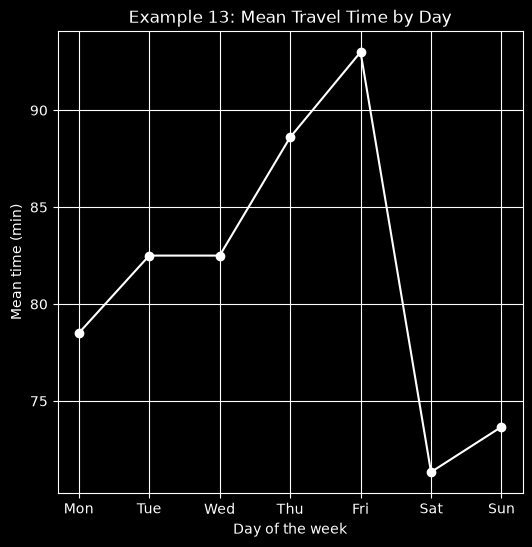

In [118]:
# Mean travel time by day of the week
day_means = trips.groupby("day_of_week")["time"].mean()

plt.plot(day_means.index, day_means.values, 'o-', color='white')
plt.xticks(range(1, 8), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.xlabel('Day of the week')
plt.ylabel('Mean time (min)')
plt.title('Example 13: Mean Travel Time by Day')
plt.grid(True)

# Display the chart
plt.show()

#### **ANOVA with More Than Two Factors**

Two-way ANOVA can be generalized to three or more factors. However, the model becomes much more complex because the effect of multiple interactions can confound the main effects of the factors themselves. With three factors A, B, and C:

$Y_{ijkl} = \mu + \alpha_i + \beta_j + \gamma_k + (\alpha\beta)_{ij} + (\alpha\gamma)_{ik} + (\beta\gamma)_{jk} + (\alpha\beta\gamma)_{ijk} + e_{ijkl}$

In `statsmodels`, simply add the factor to the formula: `"y ~ C(A) * C(B) * C(C)"`.

## **Hypothesis Testing Exercises**

### Exercise 7

Monthly aircraft sales over the past year. Test whether the data follow a normal distribution ($\alpha = 5\%$).

In [119]:
# Small sample (n = 12): Shapiro-Wilk
aircraft_sales = [48, 52, 50, 49, 47, 50, 51, 54, 39, 56, 52, 55]

w_7, p_7 = stats.shapiro(aircraft_sales)
print(f"Calculated W: {np.round(w_7, 3)}")
print(decision(p_7, 0.05))

Calculated W: 0.898
P = 0.1509 > 0.05: fail to reject H0


Note that $W_{cal} = 0.898$ and P = 0.151 > 0.05, so we fail to reject $H_0$: monthly aircraft sales follow a normal distribution. Since $n = 12$, Shapiro-Wilk is the appropriate test.

### Exercise 8

Test the normality of the temperature data ($\alpha = 5\%$).

In [120]:
# Large sample (n = 48): Kolmogorov-Smirnov
temperatures = [12.5, 14.2, 13.4, 14.6, 12.7, 10.9, 16.5, 14.7, 11.2, 10.9, 12.1, 12.8,
                13.8, 13.5, 13.2, 14.1, 15.5, 16.2, 10.8, 14.3, 12.8, 12.4, 11.4, 16.2,
                14.3, 14.8, 14.6, 13.7, 13.5, 10.8, 10.4, 11.5, 11.9, 11.3, 14.2, 11.2,
                13.4, 16.1, 13.5, 17.5, 16.2, 15.0, 14.2, 13.2, 12.4, 13.4, 12.7, 11.2]

_, d_8 = kolmogorov_smirnov(temperatures)
d_critical_8 = 1.36 / np.sqrt(len(temperatures))

print(f"Calculated D: {np.round(d_8, 3)}")
print(f"Critical D (5%): {np.round(d_critical_8, 3)}")

Calculated D: 0.085
Critical D (5%): 0.196


Note that $D_{cal} = 0.085$ is smaller than $D_c = 0.196$, so we fail to reject $H_0$: the temperatures follow a normal distribution. Since $n = 48 \geq 30$, we use Kolmogorov-Smirnov.

### Exercise 9

Final grades of two students across nine courses. Is there homogeneity of variances between the students ($\alpha = 5\%$)?

In [121]:
student_1 = [6.4, 5.8, 6.9, 5.4, 7.3, 8.2, 6.1, 5.5, 6.0]
student_2 = [6.5, 7.0, 7.5, 6.5, 8.1, 9.0, 7.5, 6.5, 6.8]

f_9, p_9 = levene(student_1, student_2)
print(f"Variances: student 1 = {np.round(np.var(student_1, ddof=1), 3)} | student 2 = {np.round(np.var(student_2, ddof=1), 3)}")
print(f"Levene F: {np.round(f_9, 3)}")
print(decision(p_9, 0.05))

Variances: student 1 = 0.84 | student 2 = 0.732
Levene F: 0.025
P = 0.8762 > 0.05: fail to reject H0


Note that the variances are similar (0.840 and 0.732), $F_{cal} = 0.025$ and P = 0.876 > 0.05, so we fail to reject $H_0$: there is homogeneity of variances between the two students' grades.

### Exercise 10

A low-fat yogurt manufacturer claims that each cup contains 60 cal. A sample of 36 cups had a mean of 65 cal and a standard deviation of 3.5. Is the claim supported ($\alpha = 5\%$)?

In [122]:
# Unknown sigma: one-sample t-test (two-tailed)
t_10, p_10 = one_sample_t_test(sample_mean=65, mu_0=60, s=3.5, n=36)

print(f"Calculated T: {np.round(t_10, 2)}")
print(f"Critical t (5%, 35 df, two-tailed): ±{np.round(t.ppf(1 - 0.05/2, 35), 3)}")
print(decision(p_10, 0.05))

Calculated T: 8.57
Critical t (5%, 35 df, two-tailed): ±2.03
P = 0.0 <= 0.05: reject H0


Note that $T_{cal} = 8.57$ is much greater than $t_c = 2.03$ (P < 0.001), so we reject $H_0$: at a 95% confidence level, the average calories per cup differs from 60 cal (the sample indicates higher calories), and the manufacturer's claim does not hold.

`NOTE:` *Since $n = 36 > 30$, a Z-test using $S$ in place of $\sigma$ would reach the same conclusion ($Z_{cal} = 8.57$).*

### Exercise 11

Waiting time for care (min) of 20 patients at each of two hospitals. Is there a difference between the mean waiting times ($\alpha = 1\%$)?

In [123]:
hospital_1 = [72, 58, 91, 88, 70, 76, 98, 101, 65, 73,
              79, 82, 80, 91, 93, 88, 97, 83, 71, 74]
hospital_2 = [66, 40, 55, 70, 76, 61, 53, 50, 47, 61,
              52, 48, 60, 72, 57, 70, 66, 55, 46, 51]

# Homogeneity of variances
_, p_levene_11 = stats.levene(hospital_1, hospital_2, center='mean')
print(f"Levene: {decision(p_levene_11, 0.01)}")

# Independent two-sample t-test
t_11, p_11 = stats.ttest_ind(hospital_1, hospital_2, equal_var=p_levene_11 > 0.01)
print(f"Means: hospital 1 = {np.mean(hospital_1)} | hospital 2 = {np.mean(hospital_2)}")
print(f"Calculated T: {np.round(t_11, 3)}")
print(decision(p_11, 0.01))

Levene: P = 0.4046 > 0.01: fail to reject H0
Means: hospital 1 = 81.5 | hospital 2 = 57.8
Calculated T: 6.921
P = 0.0 <= 0.01: reject H0


Note that the variances are homogeneous (Levene, P = 0.405), and $T_{cal} = 6.921$ with P < 0.01, so we reject $H_0$: at a 99% confidence level, the mean waiting times of the two hospitals differ (81.5 min at Hospital 1 vs. 57.8 min at Hospital 2).

### Exercise 12

LDL cholesterol levels (mg/dL) of 30 adolescents before and after a diet and physical activity treatment. Was the treatment effective ($\alpha = 5\%$)?

$H_0: \mu_d = 0$ and $H_1: \mu_d > 0$, where $d = \text{before} - \text{after}$ (right-tailed)

In [124]:
ldl_before = [220, 212, 227, 234, 204, 209, 211, 245, 237, 250,
              208, 224, 220, 218, 208, 205, 227, 207, 222, 213,
              210, 234, 240, 227, 229, 224, 204, 210, 215, 228]
ldl_after = [195, 180, 200, 204, 180, 195, 200, 210, 205, 211,
             175, 198, 195, 200, 190, 200, 222, 198, 201, 194,
             190, 204, 230, 222, 209, 198, 195, 190, 201, 210]

t_12, p_12 = stats.ttest_rel(ldl_before, ldl_after, alternative='greater')
print(f"Mean reduction: {np.round(np.mean(np.array(ldl_before) - np.array(ldl_after)), 2)} mg/dL")
print(f"Calculated T: {np.round(t_12, 3)}")
print(decision(p_12, 0.05))

Mean reduction: 20.67 mg/dL
Calculated T: 11.953
P = 0.0 <= 0.05: reject H0


Note that the mean reduction was 20.67 mg/dL, with $T_{cal} = 11.953$ and P < 0.001, so we reject $H_0$: at a 95% confidence level, the treatment reduced LDL cholesterol—that is, it was effective.

### Exercise 13

Monthly helicopter production over the last 12 months at three factories. Is there a difference among the population means ($\alpha = 5\%$)?

In [125]:
factory_1 = [24, 26, 28, 22, 31, 25, 27, 28, 30, 21, 20, 24]
factory_2 = [28, 26, 24, 30, 24, 27, 25, 29, 30, 27, 26, 25]
factory_3 = [29, 25, 24, 26, 20, 22, 22, 27, 20, 26, 24, 25]

# Assumptions
for name, group in [("Factory 1", factory_1), ("Factory 2", factory_2), ("Factory 3", factory_3)]:
    _, p_normal = stats.shapiro(group)
    print(f"Shapiro-Wilk {name}: {decision(p_normal, 0.05)}")

_, p_levene_13b = stats.levene(factory_1, factory_2, factory_3, center='mean')
print(f"Levene: {decision(p_levene_13b, 0.05)}")

Shapiro-Wilk Factory 1: P = 0.9229 > 0.05: fail to reject H0
Shapiro-Wilk Factory 2: P = 0.3298 > 0.05: fail to reject H0
Shapiro-Wilk Factory 3: P = 0.7503 > 0.05: fail to reject H0
Levene: P = 0.2324 > 0.05: fail to reject H0


In [126]:
one_way_anova(factory_1, factory_2, factory_3)

,SS,df,MS,F,P-value
Between groups,40.0556,2,20.0278,2.4761,0.0996
Within groups,266.9167,33,8.0884,NaN,NaN
Total,306.9722,35,NaN,NaN,NaN


Note that the assumptions were met (normality in each factory and Levene with P = 0.232), and $F_{cal} = 2.476$ with P = 0.0996 > 0.05, so we fail to reject $H_0$: at a 95% confidence level, there is no difference among the mean helicopter productions of the three factories.